In [102]:
# Import libraries. 

import warnings
from math import log10, floor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as colours
import cmasher as cm
from astropy.io import ascii, fits
from astropy.table import Table, join
from scipy.odr import *

# Dismissal of Depreciation Warning for cleanliness
warnings.filterwarnings("ignore", category=DeprecationWarning, module="scipy.odr")
from scipy.odr import Model, RealData, ODR

In [103]:
# Create table for final results.

# Kinematic outliers from the Kinematic-Analysis notebook
list= ["NGC362", "NGC1851", "NGC3201", "NGC6101", "NGC6218", "NGC6934", "NGC6981",
            "NGC1261", "NGC4147", "NGC5024", "NGC5053", "NGC5466", "NGC6715",
            "Arp2", "Pal12", "Terzan8", "NGC4147", "NGC4833", "NGC6584", "NGC6681"]
kinematic_outliers = set(list)

# AMR outliers from the AMR-Analysis notebook
vandenberg_outliers = {"NGC362", "NGC1261", "NGC6218", "NGC6362", "Pal12"}
krause_outliers = {"NGC362", "NGC1261", "NGC1851", "NGC6535", "Pal12"}

# Missing ages from the Krause data set
krause_missing = {"NGC4147", "Arp2", "Terzan8"}

def sort_key(name):
    digits = "".join(ch for ch in name if ch.isdigit())
    return (0, int(digits)) if name.startswith("NGC") else (1, name)

# Combine all outliers into a single list 
clusters = sorted(kinematic_outliers | vandenberg_outliers | krause_outliers, key=sort_key)
n = len(clusters)

def flag(cluster, outliers, missing=()):
    if cluster in missing:
        return "NA"
    return "✅" if cluster in outliers else "❌"

# Generate individual column lists first so we can reference them
vandenberg_flags = [flag(c, vandenberg_outliers) for c in clusters]
krause_flags = [flag(c, krause_outliers, krause_missing) for c in clusters]
kinematic_flags = [flag(c, kinematic_outliers) for c in clusters]

# Logic for Accretion Candidate: requires at least 2 checks ("✅")
def get_accretion_status(v, k, kin):
    # Count how many are strictly equal to "✅"
    checks_count = sum(1 for x in [v, k, kin] if x == "✅")
    return "✅" if checks_count >= 2 else "❌"

accretion_flags = [
    get_accretion_status(v, k, kin) 
    for v, k, kin in zip(vandenberg_flags, krause_flags, kinematic_flags)
]

results = pd.DataFrame({
    "AMR Outlier (VandenBerg)": vandenberg_flags,
    "AMR Outlier (Krause)": krause_flags,
    "Kinematic Outlier": kinematic_flags,
    "Strong Accretion Candidate": accretion_flags,
}, index=pd.Index(clusters, name="Cluster ID"))

# Decided to remove the "robust to catalogue choice" column as we are not contrasting results against other surveys as a part of this investigation. Thus, our results are the findings of the Harris, Krause, and VandenBerg data only.

# List strong accretion candidates (for ease of referencing) 
strong = results.index[results["Strong Accretion Candidate"] == "✅"].tolist()
print(f"Strong accretion candidates ({len(strong)}): {', '.join(strong)}")

results


Strong accretion candidates (5): NGC362, NGC1261, NGC1851, NGC6218, Pal12


,AMR Outlier (VandenBerg),AMR Outlier (Krause),Kinematic Outlier,Strong Accretion Candidate
Cluster ID,,,,
NGC362,✅,✅,✅,✅
NGC1261,✅,✅,✅,✅
NGC1851,❌,✅,✅,✅
NGC3201,❌,❌,✅,❌
NGC4147,❌,NA,✅,❌
NGC4833,❌,❌,✅,❌
NGC5024,❌,❌,✅,❌
NGC5053,❌,❌,✅,❌
NGC5466,❌,❌,✅,❌


In [104]:
# Set up the scatter plot for globular cluster residuals in Vandenberg vs residuals in Krause (in terms of sigma), coloured by kinematic outlier factors 

In [105]:
import re
# Set up the data for the scatter plot, including residuals and sigma values for both Vandenberg and Krause AMR fits.
data = pd.read_csv("globular_clusters_cleaned.csv")

def fit_amr(x, y, yerr=None, clip=3, niter=10):
    x, y = np.asarray(x), np.asarray(y)
    w = np.ones_like(x) if yerr is None else 1 / np.asarray(yerr)
    keep = np.ones_like(x, dtype=bool)
    for _ in range(niter):
        a, b = np.polyfit(x[keep], y[keep], 1, w=w[keep])
        resid = y - (a * x + b)
        sigma = np.std(resid[keep], ddof=2)
        new_keep = np.abs(resid) < clip * sigma
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return a, b, sigma, resid

# Fit the AMR for both Vandenberg and Krause data, calculating residuals and sigma values for each.
_, _, sigmaV, residV = fit_amr(data["FeH"], data["Age"], data["Age_err"])
data["residV"] = residV
krause = data.dropna(subset=["Age_Krause", "FeH_Krause"]).copy()
_, _, sigmaK, residK = fit_amr(krause["FeH_Krause"], krause["Age_Krause"])
krause["residK"] = residK

def find_col(df, target):
    norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
    return next(c for c in df.columns if norm(c) == norm(target))

id_col, vlsr_col, z_col = (find_col(data, c) for c in ("ClusterID", "vLSR", "Z"))

# Prepare the data for plotting, including merging Vandenberg and Krause residuals and calculating their significance in terms of sigma.
m = data[[id_col, vlsr_col, z_col, "residV"]].rename(columns={id_col: "Cluster"})
m["sigV"] = m.pop("residV") / sigmaV
k = krause[[id_col, "residK"]].rename(columns={id_col: "Cluster"})
k["sigK"] = k.pop("residK") / sigmaK
m = m.merge(k, on="Cluster", how="left")
m["na"] = m["sigK"].isna()
m["sigK"] = m["sigK"].fillna(0.0)

strong = ["NGC362", "NGC1261", "NGC1851", "NGC6218", "Pal12"]
st = m[m["Cluster"].isin(strong)]
ok, na = m[~m["na"]], m[m["na"]]
lim = np.ceil(m[["sigV", "sigK"]].abs().values.max() + 0.5)

# Set up the plotting function for the scatter plot of Vandenberg vs Krause AMR residuals, coloured by a specified column (e.g., kinematic outlier factors).
def panel(ax, col, label, cmap, unit, fmt):
    vmax = m[col].abs().max()
    kw = dict(cmap=cmap, vmin=-vmax, vmax=vmax, zorder=3)
    sc = ax.scatter(ok.sigV, ok.sigK, c=ok[col], s=70, edgecolors="k", linewidths=0.5, **kw)
    ax.scatter(na.sigV, na.sigK, c=na[col], marker="X", s=120, edgecolors="k",
               label=r"No Krause age (NA, $\sigma_K$ = 0)", **kw)
    ax.scatter(st.sigV, st.sigK, s=320, facecolors="none", edgecolors="gold",
               linewidths=2.5, label="Strong accretion candidate", zorder=4)
    for df, off, fs, wt, c in [(na, (7, -14), 8, "normal", "k"),
                               (st, (9, 9), 10, "bold", "darkgoldenrod")]:
        for r in df.itertuples():
            ax.annotate(r.Cluster, (r.sigV, r.sigK), xytext=off, textcoords="offset points",
                        fontsize=fs, weight=wt, color=c)
    ax.axhline(0, c="k", lw=0.8); ax.axvline(0, c="k", lw=0.8)
    for t in (-2, 2):
        ax.axhline(t, c="r", ls="--", lw=1); ax.axvline(t, c="r", ls="--", lw=1)
    ax.plot([-lim, lim], [-lim, lim], c="grey", ls=":", label="1:1")
    plt.colorbar(sc, ax=ax, label=label)
    txt = "\n".join(["Strong accretion candidates:"] +
                    [f"{r.Cluster}: V {r.sigV:+.1f}$\\sigma$, K {r.sigK:+.1f}$\\sigma$, "
                     f"{fmt.format(getattr(r, col))} {unit}" for r in st.itertuples()])
    ax.text(0.02, 0.97, txt, transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9))
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim),
           xlabel=r"VandenBerg AMR residual ($\sigma$)",
           ylabel=r"Krause AMR residual ($\sigma$)",
           title=f"VandenBerg vs. Krause AMR Residuals, coloured by {label.split(' (')[0]}")
    ax.legend(loc="lower right", fontsize=8)

## Plot 1: VandenBerg vs Krause AMR significance, coloured by v_LSR (radial velocity corrected to the Local Standard of Rest (LSR))

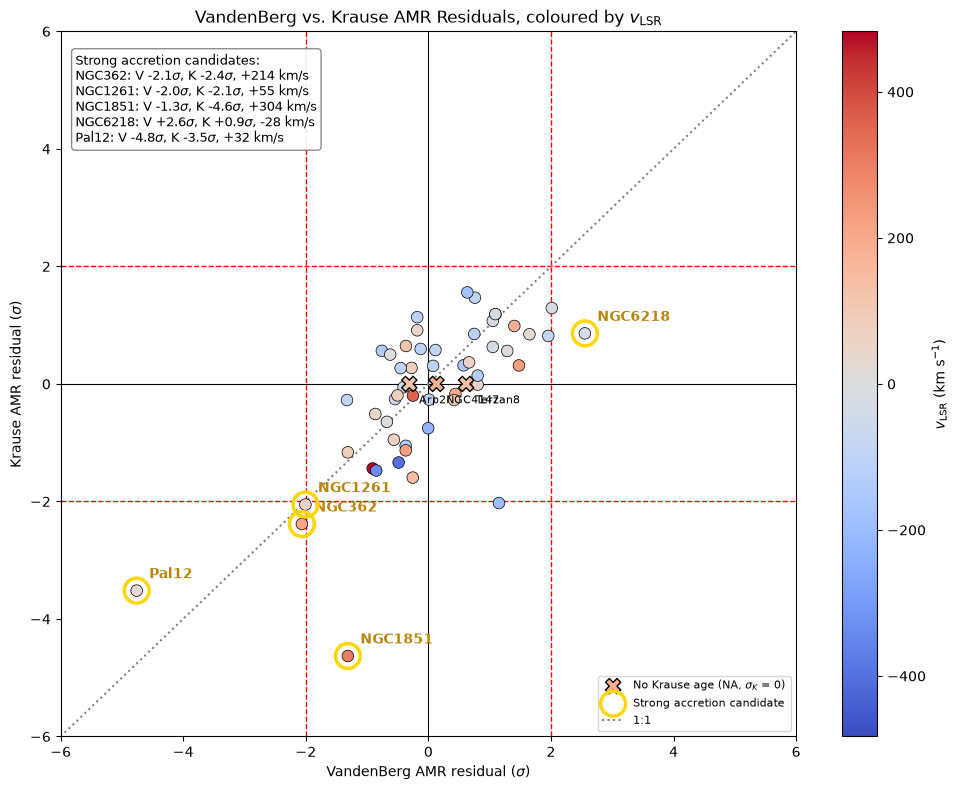

In [106]:
# Set up the scatter plot for globular cluster residuals in Vandenberg vs residuals in Krause (in terms of sigma), coloured by v_LSR. 
fig, ax = plt.subplots(figsize=(10, 8))
panel(ax, vlsr_col, r"$v_{\rm LSR}$ (km s$^{-1}$)", "coolwarm", "km/s", "{:+.0f}")
plt.tight_layout()
plt.savefig("amr_vdb_vs_krause_vlsr.png", dpi=200)
plt.show()

## Plot 2: VandenBerg vs Krause AMR significance, coloured by z (height above/below the Galactic plane).

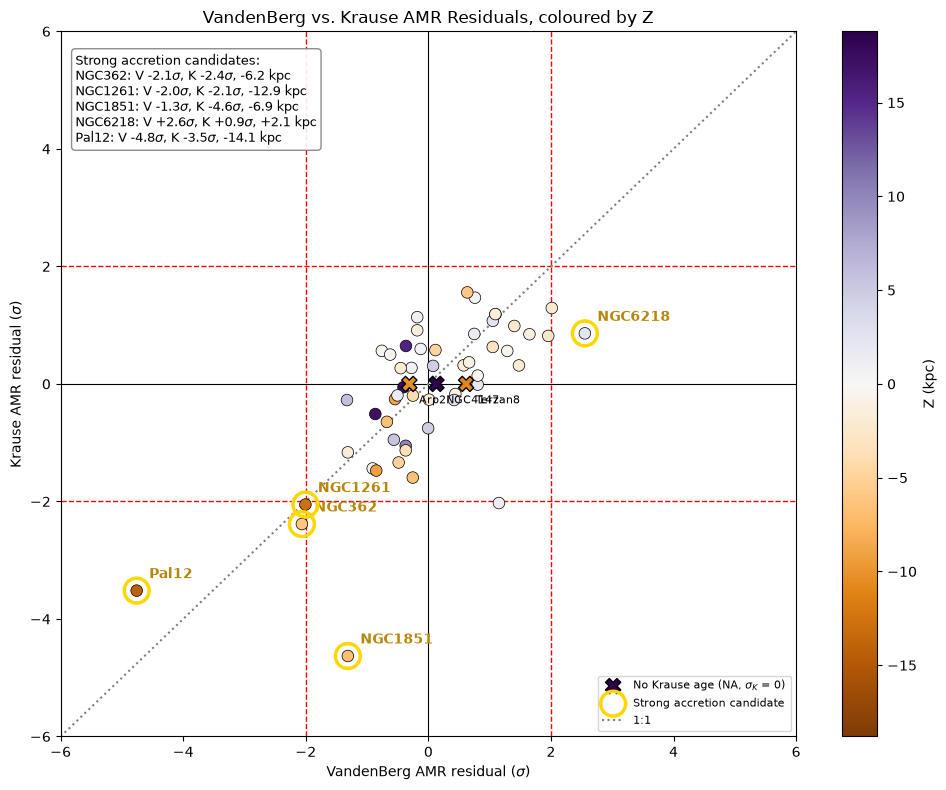

In [107]:
# Set up the scatter plot for globular cluster residuals in Vandenberg vs residuals in Krause (in terms of sigma), coloured by z (height above/below the Galactic plane).
fig, ax = plt.subplots(figsize=(10, 8))
panel(ax, z_col, "Z (kpc)", "PuOr", "kpc", "{:+.1f}")
plt.tight_layout()
plt.savefig("amr_vdb_vs_krause_z.png", dpi=200)
plt.show()